In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2', 'mcevi']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']
df_all = getData(observables1+observabless1, '/nfs/roberts/home/ys668/output/run12/all050124_rc.root', "MatchedTree")

In [5]:
def delta_phi(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2 * np.pi - diff)
dphi1 = delta_phi(df_all['phi1'].values, df_all['phi1s'].values)
dphi2 = delta_phi(df_all['phi2'].values, df_all['phi2s'].values)
df_all['distance1'] = np.sqrt(dphi1**2 + (df_all['y1'].values - df_all['y1s'].values)**2)
df_all['distance2'] = np.sqrt(dphi2**2 + (df_all['y2'].values - df_all['y2s'].values)**2)

In [3]:
df_all = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc.csv', low_memory=False)
df_all

,pt,b,w,y1,y2,phi1,phi2,mcevi,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2
0,6.909035,-1,1.335866e-10,-0.566667,-0.581373,0.254736,0.123353,1,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,8.941545,8.884809
1,7.770895,-9,1.335866e-10,-9.000000,-9.000000,-9.000000,-9.000000,2,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
2,5.072170,1,1.335866e-10,-0.282474,-0.409867,5.993405,0.018299,4,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.323278,9.015056
3,7.017721,1,1.335866e-10,0.213610,-0.212909,2.084065,2.228717,7,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,10.389372,10.083217
4,10.088763,-1,1.335866e-10,0.446627,0.397990,5.020298,5.315151,8,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.210720,12.362633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21473756,5.589589,-1,3.372111e-10,-0.138695,0.013598,5.879950,6.135971,30487746,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,12.346136,12.633953
21473757,5.198447,-9,3.372111e-10,-9.000000,-9.000000,-9.000000,-9.000000,30487747,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
21473758,12.328792,-1,3.372111e-10,-0.236462,0.165022,4.458089,4.457092,30487750,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.326025,11.638839
21473759,8.193869,-1,3.372111e-10,-0.508361,-0.585699,4.988478,4.940525,30487754,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.466449,11.376964


In [6]:
#df_all = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc.csv', low_memory=False)
df_all

,pt,b,w,y1,y2,phi1,phi2,mcevi,pts,bs,ws,y1s,y2s,phi1s,phi2s,nefs,distance1,distance2
0,6.909035,-1,1.335866e-10,-0.566667,-0.581373,0.254736,0.123353,1,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,8.941545,8.884809
1,7.770895,-9,1.335866e-10,-9.000000,-9.000000,-9.000000,-9.000000,2,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
2,5.072170,1,1.335866e-10,-0.282474,-0.409867,5.993405,0.018299,4,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.323278,9.015056
3,7.017721,1,1.335866e-10,0.213610,-0.212909,2.084065,2.228717,7,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,10.389372,10.083217
4,10.088763,-1,1.335866e-10,0.446627,0.397990,5.020298,5.315151,8,-9.0,-9,0.000000e+00,-9.0,-9.0,-9.0,-9.0,-9.0,12.210720,12.362633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21473756,5.589589,-1,3.372111e-10,-0.138695,0.013598,5.879950,6.135971,30487746,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,12.346136,12.633953
21473757,5.198447,-9,3.372111e-10,-9.000000,-9.000000,-9.000000,-9.000000,30487747,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,0.000000,0.000000
21473758,12.328792,-1,3.372111e-10,-0.236462,0.165022,4.458089,4.457092,30487750,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.326025,11.638839
21473759,8.193869,-1,3.372111e-10,-0.508361,-0.585699,4.988478,4.940525,30487754,-9.0,-9,3.372111e-10,-9.0,-9.0,-9.0,-9.0,-9.0,11.466449,11.376964


In [7]:
odd = []
even = []
for i in range(0, df_all.shape[0]):
    if (df_all.iloc[i]['mcevi'] % 2 == 0):
        even.append(i)
    else:
        odd.append(i)

In [5]:
df1_all = df_all.iloc[odd]
df2_all = df_all.iloc[even]
df1_all.shape[0],df2_all.shape[0]

(10735656, 10738105)

In [5]:
df1_all = df_all.iloc[odd]
df2_all = df_all.iloc[even]
df1_all.shape[0],df2_all.shape[0]

(10735656, 10738105)

In [6]:
df1_allreco = applyCut(df1_all, 'pts>15 and bs!=-9 and w<1')
df2_allreco = applyCut(df2_all, 'pts>15 and bs!=-9 and w<1')
df1_alltruth = applyCut(df1_all, 'pt>5 and b!=-9 and w<1')
df2_alltruth = applyCut(df2_all, 'pt>5 and b!=-9 and w<1')

Process sample 1

In [7]:
df1_allfake = applyCut(df1_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df1_match = applyCut(df1_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [8]:
df1_allreco_pts_array = [ df1_allreco[(df1_allreco.pts>15) & (df1_allreco.pts<20)],\
                       df1_allreco[(df1_allreco.pts>20) & (df1_allreco.pts<25)],\
                       df1_allreco[(df1_allreco.pts>25) & (df1_allreco.pts<30)],\
                       df1_allreco[(df1_allreco.pts>30) & (df1_allreco.pts<40)],\
                       df1_allreco[(df1_allreco.pts>40) & (df1_allreco.pts<60)] ]

df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

df1_allfake_pts_array = [ df1_allfake[(df1_allfake.pts>15) & (df1_allfake.pts<20)],\
                       df1_allfake[(df1_allfake.pts>20) & (df1_allfake.pts<25)],\
                       df1_allfake[(df1_allfake.pts>25) & (df1_allfake.pts<30)],\
                       df1_allfake[(df1_allfake.pts>30) & (df1_allfake.pts<40)],\
                       df1_allfake[(df1_allfake.pts>40) & (df1_allfake.pts<60)]  ]

In [9]:
rc1_allreco_bs_vs_pts_array = []
rc1_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df1_allreco_pts_array)):
    rc1_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[0])
    rc1_err_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df1_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df1_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[1])

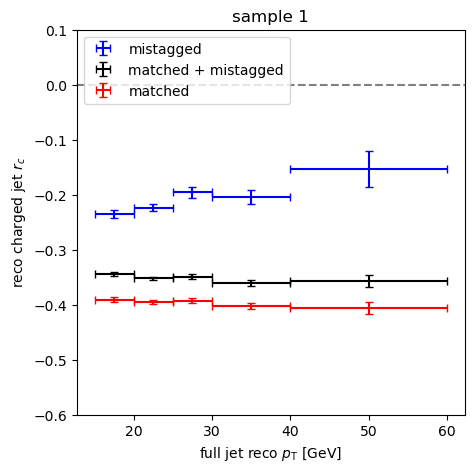

In [10]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]')
plt.title('sample 1')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [11]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [12]:
b1_fake_array = []
b1_err_fake_array = []
for i in range(0,5):
    df1_fake_pts = df1_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df1_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_fake_pts['ws'], density=True)
    b1_fake_array.append(y_fake_rec/sum(y_fake_rec))
    b1_err_fake_array.append(yerr_fake_rec/sum(y_fake_rec))

In [13]:
b1_match_array = []
b1_err_match_array = []
for i in range(0,5):
    df1_match_pts = df1_match_pts_array[i]
    y_match_rec,yerr_match_rec,x = calc_hist(df1_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_match_pts['ws'], density=True)
    b1_match_array.append(y_match_rec/sum(y_match_rec))
    b1_err_match_array.append(yerr_match_rec/sum(y_match_rec))

In [14]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df1_allreco['pts'], bins=binedges, weights=df1_allreco['ws'])
match, _ = np.histogram(df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_618140/2916068059.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [15]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29807466, 0.24953981, 0.22208758, 0.21034853, 0.19688038])

Process sample 2

In [16]:
df2_allfake = applyCut(df2_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df2_match = applyCut(df2_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [17]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)],\
                       df2_allreco[(df2_allreco.pts>40) & (df2_allreco.pts<60)] ]

df2_match_pts_array = [ df2_match[(df2_match.pts>15) & (df2_match.pts<20)],\
                       df2_match[(df2_match.pts>20) & (df2_match.pts<25)],\
                       df2_match[(df2_match.pts>25) & (df2_match.pts<30)],\
                       df2_match[(df2_match.pts>30) & (df2_match.pts<40)],\
                       df2_match[(df2_match.pts>40) & (df2_match.pts<60)] ]

df2_allfake_pts_array = [ df2_allfake[(df2_allfake.pts>15) & (df2_allfake.pts<20)],\
                       df2_allfake[(df2_allfake.pts>20) & (df2_allfake.pts<25)],\
                       df2_allfake[(df2_allfake.pts>25) & (df2_allfake.pts<30)],\
                       df2_allfake[(df2_allfake.pts>30) & (df2_allfake.pts<40)],\
                       df2_allfake[(df2_allfake.pts>40) & (df2_allfake.pts<60)] ]

In [18]:
rc2_allreco_bs_vs_pts_array = []
rc2_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df2_allreco_pts_array)):
    rc2_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[0])
    rc2_err_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df2_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df2_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[1])

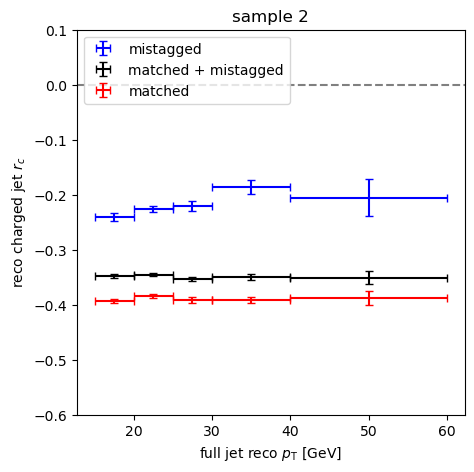

In [19]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]')
plt.title('sample 2')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [20]:
b2_allreco_array = []
b2_err_allreco_array = []
for i in range(0,5):
    df2_allreco_pts = df2_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df2_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df2_allreco_pts['ws'], density=True)
    b2_allreco_array.append(y_reco/sum(y_reco))
    b2_err_allreco_array.append(yerr_reco/sum(y_reco))

# 1. Mistagged subtraction

In [ ]:
def subtractFake(data, fake_rate, fake_dist):
    corrected = (data - fake_rate * fake_dist)/(1 - fake_rate)
    return corrected

In [22]:
b2_fakesubtracted_array = []
b2_err_fakesubtracted_array = []
rc_fakesubtracted_array = []
rc_err_fakesubtracted_array = []
for i in range(0,5):
    print(i)
    #print(b2_allreco_array[i])
    #print(getRc(data_array[i]))
    b2_fakesubtracted = subtractFake(b2_allreco_array[i], fake_rate_array[i], b1_fake_array[i])
    b2_fakesubtracted_array.append(b2_fakesubtracted)
    b2_err_fakesubtracted = np.sqrt(b2_err_allreco_array[i]**2+(fake_rate_array[i]*b1_err_fake_array[i])**2)
    # overestimation compared to correction_nominal_detail
    b2_err_fakesubtracted_array.append(b2_err_fakesubtracted)
    print(b2_fakesubtracted, b2_err_fakesubtracted)
    nos = b2_fakesubtracted[0]
    nss = b2_fakesubtracted[1]
    rc_fakesubtracted = (nss-nos) / (nss+nos)
    rc_fakesubtracted_array.append(rc_fakesubtracted)
    rc_err_fakesubtracted = 2*b2_err_fakesubtracted[0]
    rc_err_fakesubtracted_array.append(rc_err_fakesubtracted)
    p = nss/(nos+nss)
    q = nos/(nos+nss)

0
[0.69772172 0.30227828] [0.00371671 0.0025024 ]
1
[0.69270518 0.30729482] [0.00306769 0.00218139]
2
[0.69904902 0.30095098] [0.00418207 0.00302341]
3
[0.69404394 0.30595606] [0.00516802 0.00374297]
4
[0.69975204 0.30024796] [0.01122166 0.00876144]


# 2. $p_T$ correction

In [24]:
reweight_array = []
reweight_err_array = []
for i in range(0,5):
    numerator = b2_fakesubtracted_array[i]/sum(b2_fakesubtracted_array[i])
    denominator = b1_match_array[i]/sum(b1_match_array[i])
    numerator_err = b2_err_fakesubtracted_array[i]/sum(b2_fakesubtracted_array[i])
    denominator_err = b1_err_match_array[i]/sum(b1_match_array[i])
    reweight = numerator/denominator
    reweight_err = reweight*np.sqrt((numerator_err/numerator)**2+(denominator_err/denominator)**2)
    reweight_array.append(reweight)
    reweight_err_array.append(reweight_err)

In [25]:
reweight_array

[array([1.0031211 , 0.99286948]),
 array([0.9932007 , 1.01567382]),
 array([1.00393756, 0.99097195]),
 array([0.9900316 , 1.02337431]),
 array([0.99501136, 1.01182288])]

In [26]:
reweight_err_array

[array([0.00800199, 0.01186486]),
 array([0.00643629, 0.01010954]),
 array([0.0086508 , 0.01335075]),
 array([0.01058006, 0.0172937 ]),
 array([0.02264503, 0.03633266])]

Reweight sample 1

In [27]:
r = []
for i in range(0, df1_match.shape[0]):
    if (df1_match.iloc[i]['pts'] > 15 and df1_match.iloc[i]['pts'] < 20):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df1_match.iloc[i]['pts'] > 20 and df1_match.iloc[i]['pts'] < 25):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df1_match.iloc[i]['pts'] > 25 and df1_match.iloc[i]['pts'] < 30):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df1_match.iloc[i]['pts'] > 30 and df1_match.iloc[i]['pts'] < 40):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df1_match.iloc[i]['pts'] > 40 and df1_match.iloc[i]['pts'] < 60):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df1_match.iloc[i]['pts'])
df1_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.15032283200955
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 63.19369788337173
anomaly reco pT: 62.74602930593176
anomaly reco pT: 60.03476303183356
anomaly reco pT: 66.83963074901102
anomaly reco pT: 70.61911542903617
anomaly reco pT: 67.1333301990355
anomaly reco pT: 66.47620481622019
anomaly reco pT: 60.54009807311778
anomaly reco pT: 60.55736397596093
anomaly reco pT: 62.79625438717492
anomaly reco pT: 64.06767594033505
anomaly reco pT: 62.35196005363901
anomaly reco pT: 60.050811324850045
anomaly reco pT: 60.946039716285206
anomaly reco pT: 68.10225321467055
anomaly reco pT: 60.9799540425152
anomaly reco pT: 65.16160073216953
anomaly reco pT: 60.0973570676119
anomaly reco pT: 63.822436599165
anomaly reco pT: 74.8368

anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 60.80583130708745
anomaly reco pT: 62.728856238000006
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 62.7859012143824
anomaly reco pT: 66.29737410911332
anomaly reco pT: 63.565336097220666
anomaly reco pT: 63.24551244561167
anomaly reco pT: 62.089369272962
anomaly reco pT: 63.9898512281929
anomaly reco pT: 67.34392454437194
anomaly reco pT: 60.30194368134946
anomaly reco pT: 62.66671837648719
anomaly reco pT: 62.53122089793198
anomaly reco pT: 62.00414824509995
anomaly reco pT: 68.69509447406367
anomaly reco pT: 63.92488173952949
anomaly reco pT: 63.775740988168806
anomaly reco pT: 65.40048930397595
anomaly reco pT: 61.0053162633842
anomaly reco pT: 65.26514207685892
anomaly reco pT: 67.32893261745757
anomaly reco pT: 60.15048352645918
anomaly reco pT: 62.15602295447404
anomaly reco pT: 63.52619916634279
anomaly reco pT: 62.534

anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 66.14452877031708
anomaly reco pT: 60.79420789744857
anomaly reco pT: 61.510335938526346
anomaly reco pT: 63.60463563764089
anomaly reco pT: 63.84290622372178
anomaly reco pT: 60.24441190326755
anomaly reco pT: 61.89856794874568
anomaly reco pT: 62.71933550193654
anomaly reco pT: 60.37218127058552
anomaly reco pT: 67.35165154282551
anomaly reco pT: 62.938599711603416
anomaly reco pT: 62.01210782743407
anomaly reco pT: 60.09198704471758
anomaly reco pT: 60.17424504803381
anomaly reco pT: 60.10060638205464
anomaly reco pT: 63.40587043188994
anomaly reco pT: 65.75117536986112
anomaly reco pT: 61.4706264844495
anomaly reco pT: 61.18929718786077
anomaly reco pT: 72.35126700760344
anomaly reco pT: 60.24854076145046
anomaly reco pT: 60.06684474591112
anomaly reco pT: 66.72767965295104
anomaly reco pT: 61.75922728597852
anomaly reco pT: 60.466287718503104
anomaly reco pT: 63.37563097869944
anomaly reco pT: 7

anomaly reco pT: 74.15077360023288
anomaly reco pT: 62.990262949112
anomaly reco pT: 60.70855166792012
anomaly reco pT: 75.47290057361973
anomaly reco pT: 61.891682077155146
anomaly reco pT: 63.65350555918853
anomaly reco pT: 60.502287198324034
anomaly reco pT: 62.140137226882494
anomaly reco pT: 60.58973760184473
anomaly reco pT: 68.25018575589665
anomaly reco pT: 60.62101269715139
anomaly reco pT: 63.44703339840572
anomaly reco pT: 61.144122126022445
anomaly reco pT: 62.56903826851902
anomaly reco pT: 65.13405587967877
anomaly reco pT: 65.38701159958929
anomaly reco pT: 62.49970092892863
anomaly reco pT: 60.02989932384669
anomaly reco pT: 60.71988932720338
anomaly reco pT: 65.94239898782774
anomaly reco pT: 62.20716417328564
anomaly reco pT: 61.925664449411656
anomaly reco pT: 61.55536404443391
anomaly reco pT: 65.29376223003007
anomaly reco pT: 60.32571235212267
anomaly reco pT: 62.91918596007402
anomaly reco pT: 60.05665446904023
anomaly reco pT: 65.23323863731325
anomaly reco pT: 

anomaly reco pT: 61.02055470698796
anomaly reco pT: 61.352032860227496
anomaly reco pT: 65.21758701517287
anomaly reco pT: 64.78416612925247
anomaly reco pT: 63.235413288444384
anomaly reco pT: 63.885376662169264
anomaly reco pT: 60.19347808119953
anomaly reco pT: 60.47824318529232
anomaly reco pT: 66.09377021895335
anomaly reco pT: 63.3563445698343
anomaly reco pT: 60.61307890828269
anomaly reco pT: 61.812546681147445
anomaly reco pT: 61.22263259179611
anomaly reco pT: 62.10461901322725
anomaly reco pT: 61.65273190278186
anomaly reco pT: 60.271136906948016
anomaly reco pT: 63.8893393978292
anomaly reco pT: 62.696769386279406
anomaly reco pT: 60.72319983920541
anomaly reco pT: 61.37137376468045
anomaly reco pT: 61.479023951528326
anomaly reco pT: 60.919787226192526
anomaly reco pT: 62.24869291033049
anomaly reco pT: 63.28715507428068
anomaly reco pT: 63.41361560964472
anomaly reco pT: 62.55423716214696
anomaly reco pT: 65.15196497572471
anomaly reco pT: 66.84592083340063
anomaly reco p

anomaly reco pT: 60.74841930645484
anomaly reco pT: 60.373843469716896
anomaly reco pT: 60.69842122566675
anomaly reco pT: 63.40558697565748
anomaly reco pT: 63.71849778104768
anomaly reco pT: 63.16619190421466
anomaly reco pT: 60.73525645953942
anomaly reco pT: 68.98137441094258
anomaly reco pT: 66.30746246808405
anomaly reco pT: 61.78542729895869
anomaly reco pT: 61.4551951419788
anomaly reco pT: 60.001845894717306
anomaly reco pT: 62.42401126121896
anomaly reco pT: 64.44676526803873
anomaly reco pT: 65.71238203317557
anomaly reco pT: 60.80231019786999
anomaly reco pT: 63.796859766694894
anomaly reco pT: 64.7212331231633
anomaly reco pT: 66.9737490149431
anomaly reco pT: 62.49252090258781
anomaly reco pT: 60.4232529391896
anomaly reco pT: 61.52524742781658
anomaly reco pT: 61.857276136187565
anomaly reco pT: 63.173386395884165
anomaly reco pT: 62.5065884493529
anomaly reco pT: 60.09901646616154
anomaly reco pT: 63.64440125353295
anomaly reco pT: 60.216931357438085
anomaly reco pT: 64

... (16 outputs left out)

anomaly reco pT: 61.50479012982503
anomaly reco pT: 60.21080996539269
anomaly reco pT: 68.35290568359687
anomaly reco pT: 62.91566522543437
anomaly reco pT: 60.44382047641504
anomaly reco pT: 60.66168202796234
anomaly reco pT: 60.79437977906816
anomaly reco pT: 60.79357876934058
anomaly reco pT: 62.789177166826654
anomaly reco pT: 61.31300754083087
anomaly reco pT: 66.44394701689754
anomaly reco pT: 61.2909641315065
anomaly reco pT: 65.02845954195612
anomaly reco pT: 68.1539424179393
anomaly reco pT: 63.402024780763824
anomaly reco pT: 69.01165207092109
anomaly reco pT: 63.19551612515797
anomaly reco pT: 64.18303416632877
anomaly reco pT: 63.64717262199085
anomaly reco pT: 63.092421690093886
anomaly reco pT: 61.94837485205381
anomaly reco pT: 61.51594101170776
anomaly reco pT: 61.24742496667652
anomaly reco pT: 64.12927240205535
anomaly reco pT: 70.65851332813678
anomaly reco pT: 61.68789007548849
anomaly reco pT: 66.52290729836726
anomaly reco pT: 63.6719596682024
anomaly reco pT: 61.

anomaly reco pT: 61.27199786672677
anomaly reco pT: 63.90524248470502
anomaly reco pT: 61.98661653439088
anomaly reco pT: 62.41592684385443
anomaly reco pT: 63.72657281313012
anomaly reco pT: 60.67510521196438
anomaly reco pT: 60.20463716213028
anomaly reco pT: 61.679730162669145
anomaly reco pT: 60.80617008343579
anomaly reco pT: 60.65688193134115
anomaly reco pT: 64.03002635848641
anomaly reco pT: 61.56846855404998
anomaly reco pT: 62.93070624119498
anomaly reco pT: 63.72387543388114
anomaly reco pT: 62.68907511629273
anomaly reco pT: 64.83681382191166
anomaly reco pT: 60.20120183851201
anomaly reco pT: 66.36233679116651
anomaly reco pT: 63.88107340971264
anomaly reco pT: 62.26043434222397
anomaly reco pT: 65.29397266999887
anomaly reco pT: 63.0049967696562
anomaly reco pT: 60.19496820024056
anomaly reco pT: 60.41940791707295
anomaly reco pT: 63.20511815266658
anomaly reco pT: 61.77784128793783
anomaly reco pT: 60.04238848817945
anomaly reco pT: 63.738405289465405
anomaly reco pT: 63

anomaly reco pT: 60.303759511477935
anomaly reco pT: 62.32698069264111
anomaly reco pT: 60.00478994632899
anomaly reco pT: 63.403271181078914
anomaly reco pT: 62.53458542765311
anomaly reco pT: 61.754438121186
anomaly reco pT: 60.48476719345234
anomaly reco pT: 62.32565679963697
anomaly reco pT: 62.43500761803754
anomaly reco pT: 60.40692758389495
anomaly reco pT: 61.476661485146
anomaly reco pT: 61.96365584249061
anomaly reco pT: 60.23695838987487
anomaly reco pT: 71.60701002835559
anomaly reco pT: 63.56514320295907
anomaly reco pT: 62.22550121903247
anomaly reco pT: 61.09090956196156
anomaly reco pT: 63.23312395465088
anomaly reco pT: 65.96302798676528
anomaly reco pT: 61.09552947718905
anomaly reco pT: 61.98946986641298
anomaly reco pT: 61.11565162412116
anomaly reco pT: 60.04634532820712
anomaly reco pT: 60.46021517963606
anomaly reco pT: 60.02980290742159
anomaly reco pT: 69.19941044301783
anomaly reco pT: 61.29445689114465
anomaly reco pT: 65.0235397656114
anomaly reco pT: 60.095

/tmp/ipykernel_618140/1025607542.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_match['r'] = r #


In [42]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    print(p)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [115]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]

In [116]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[1])

0.30391925932381725
0.30391925932381725
0.3118212121683954
0.3118212121683954
0.3125148559635339
0.3125148559635339
0.31195455147204987
0.31195455147204987
0.3249185618916001
0.3249185618916001


In [117]:
print(rc_match_bs_vs_pt_array)
print(rc_err_match_bs_vs_pt_array)

[-0.3921614813523656, -0.3763575756632091, -0.37497028807293215, -0.37609089705590026, -0.3501628762167997]
[0.003883728016270727, 0.0030800190260907197, 0.0038548825051344495, 0.004847937448414144, 0.007463184198153787]


# Check corrected result against thesis formula

In [32]:
binedges = np.array([15, 20, 25, 30, 40, 60])

In [33]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p_final = nss/(nss+nos)
    print(p_final)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err, p_final

## Truth $p_T\in$ (15, 20) GeV

In [85]:
df1_match_cut = applyCut(df1_match, '15<pt<20')
df1_match_pts_array = [ df1_match_cut[(df1_match_cut.pts>15) & (df1_match_cut.pts<20)],\
                       df1_match_cut[(df1_match_cut.pts>20) & (df1_match_cut.pts<25)],\
                       df1_match_cut[(df1_match_cut.pts>25) & (df1_match_cut.pts<30)],\
                       df1_match_cut[(df1_match_cut.pts>30) & (df1_match_cut.pts<40)],\
                       df1_match_cut[(df1_match_cut.pts>40) & (df1_match_cut.pts<60)] ]

In [86]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df1_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.30718722876172183
0.2883136324232587
0.24076508104605066
0.3671782897337397
0.27126421540981366


In [87]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '15<pt<20 and bs==1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>15) & (df1_match_cut.pt<20)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>15) & (df1_match_cut.pt<20)]['w']))
prob_array

[0.9216652756159053,
 0.07707420387661312,
 0.0012113198672483387,
 4.756262679944871e-05,
 1.635695848781478e-06]

In [88]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3039821525914443

In [91]:
rc_rwerr_match_bs_vs_pt_array = []

In [92]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0033667291994664054


In [39]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '15<pt<20 and bs==-1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>15) & (df1_match_cut.pt<20)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>15) & (df1_match_cut.pt<20)]['w']))
prob_array

[0.9145736885890439,
 0.08370767229137094,
 0.0016806383258768651,
 3.606641338616815e-05,
 1.9333607163604314e-06]

In [40]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6960795193860202

In [41]:
0.3039821525914443/(0.3039821525914443+0.6960795193860202)

0.3039634065670845

## Truth $p_T\in$ (20,25) GeV

In [93]:
df1_match_cut = applyCut(df1_match, '20<pt<25')
df1_match_pts_array = [ df1_match_cut[(df1_match_cut.pts>15) & (df1_match_cut.pts<20)],\
                       df1_match_cut[(df1_match_cut.pts>20) & (df1_match_cut.pts<25)],\
                       df1_match_cut[(df1_match_cut.pts>25) & (df1_match_cut.pts<30)],\
                       df1_match_cut[(df1_match_cut.pts>30) & (df1_match_cut.pts<40)],\
                       df1_match_cut[(df1_match_cut.pts>40) & (df1_match_cut.pts<60)] ]

In [94]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df1_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.31855741027477424
0.3061158957802535
0.2946426490549949
0.24883259951088496
0.02483352340422729


In [95]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '20<pt<25 and bs==1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>20) & (df1_match_cut.pt<25)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>20) & (df1_match_cut.pt<25)]['w']))
prob_array

[0.40934421229525403,
 0.5330999235032953,
 0.055916494733237884,
 0.0016369917982848382,
 2.348346094046317e-06]

In [96]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.31196155250796925

In [97]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0022724327086974688


In [50]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '20<pt<25 and bs==-1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>20) & (df1_match_cut.pt<25)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>20) & (df1_match_cut.pt<25)]['w']))
prob_array

[0.3939147443283835,
 0.5436028166358398,
 0.0602178917229128,
 0.0022230435991182664,
 4.148341919609714e-05]

In [51]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6882366188929091

In [52]:
0.31196155250796925/(0.31196155250796925+0.6882366188929091)

0.31189974289898537

## Truth $p_T\in$ (25, 30) GeV

In [98]:
df1_match_cut = applyCut(df1_match, '25<pt<30')
df1_match_pts_array = [ df1_match_cut[(df1_match_cut.pts>15) & (df1_match_cut.pts<20)],\
                       df1_match_cut[(df1_match_cut.pts>20) & (df1_match_cut.pts<25)],\
                       df1_match_cut[(df1_match_cut.pts>25) & (df1_match_cut.pts<30)],\
                       df1_match_cut[(df1_match_cut.pts>30) & (df1_match_cut.pts<40)],\
                       df1_match_cut[(df1_match_cut.pts>40) & (df1_match_cut.pts<60)] ]

In [99]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df1_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.30375140591524374
0.3234073417245726
0.30735582127476524
0.2875788585329826
0.1339099460735434


In [100]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '25<pt<30 and bs==1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>25) & (df1_match_cut.pt<30)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>25) & (df1_match_cut.pt<30)]['w']))
prob_array

[0.11214253196665168,
 0.3918204413077908,
 0.4365063817535804,
 0.05942491859436154,
 0.00010556738663099405]

In [101]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3129789735443812

In [102]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0022583396105901577


In [58]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '25<pt<30 and bs==-1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>25) & (df1_match_cut.pt<30)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>25) & (df1_match_cut.pt<30)]['w']))
prob_array

[0.11639843836931552,
 0.3711891366693032,
 0.4454409142006293,
 0.06666213221747705,
 0.0003091795412633607]

In [59]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6877628903646981

In [60]:
0.3129789735443812/(0.3129789735443812+0.6877628903646981)

0.3127469578636678

## Truth $p_T\in$ (30, 40) GeV

In [103]:
df1_match_cut = applyCut(df1_match, '30<pt<40')
df1_match_pts_array = [ df1_match_cut[(df1_match_cut.pts>15) & (df1_match_cut.pts<20)],\
                       df1_match_cut[(df1_match_cut.pts>20) & (df1_match_cut.pts<25)],\
                       df1_match_cut[(df1_match_cut.pts>25) & (df1_match_cut.pts<30)],\
                       df1_match_cut[(df1_match_cut.pts>30) & (df1_match_cut.pts<40)],\
                       df1_match_cut[(df1_match_cut.pts>40) & (df1_match_cut.pts<60)] ]

In [104]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df1_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.27951368523980896
0.31400457086458916
0.31987035774123973
0.303952520535493
0.28699791609228636


In [105]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '30<pt<40 and bs==1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>30) & (df1_match_cut.pt<40)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>30) & (df1_match_cut.pt<40)]['w']))
prob_array

[0.04222726660235133,
 0.1229980615126144,
 0.3310142335658948,
 0.48729085850661225,
 0.01646890860509223]

In [106]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.31222973557969247

In [107]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.0029598523640527973


In [66]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '30<pt<40 and bs==-1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>30) & (df1_match_cut.pt<40)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>30) & (df1_match_cut.pt<40)]['w']))
prob_array

[0.048631679380472644,
 0.12005690850282315,
 0.3144618847577289,
 0.4985687082170647,
 0.018280181877991554]

In [67]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6882002924431344

In [68]:
0.31222973557969247/(0.31222973557969247+0.6882002924431344)

0.31209552575781774

## Truth $p_T\in$ (40, 60) GeV

In [108]:
df1_match_cut = applyCut(df1_match, '40<pt<60')
df1_match_pts_array = [ df1_match_cut[(df1_match_cut.pts>15) & (df1_match_cut.pts<20)],\
                       df1_match_cut[(df1_match_cut.pts>20) & (df1_match_cut.pts<25)],\
                       df1_match_cut[(df1_match_cut.pts>25) & (df1_match_cut.pts<30)],\
                       df1_match_cut[(df1_match_cut.pts>30) & (df1_match_cut.pts<40)],\
                       df1_match_cut[(df1_match_cut.pts>40) & (df1_match_cut.pts<60)] ]

In [109]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
p_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pts_array)):
    rc, rc_err, p = getRcAndErr(df1_match_pts_array[i], 'bs')
    rc_match_bs_vs_pt_array.append(rc)
    rc_err_match_bs_vs_pt_array.append(rc_err)
    p_match_bs_vs_pt_array.append(p)

0.2850312389912867
0.3130503924074071
0.32129650449069125
0.3300458638890477
0.3115129627884604


In [110]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '40<pt<60 and bs==1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>40) & (df1_match_cut.pt<60)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>40) & (df1_match_cut.pt<60)]['w']))
prob_array

[0.014240821951970288,
 0.033758359930249886,
 0.0760828210549639,
 0.46721514997370855,
 0.4076764436019136]

In [111]:
reweight_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0]+reweight_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1]+\
reweight_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2]+reweight_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3]+\
reweight_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4]

0.3252930625099584

In [112]:
p_err = np.sqrt((reweight_err_array[0][1]*p_match_bs_vs_pt_array[0]*prob_array[0])**2+\
        (reweight_err_array[1][1]*p_match_bs_vs_pt_array[1]*prob_array[1])**2+\
        (reweight_err_array[2][1]*p_match_bs_vs_pt_array[2]*prob_array[2])**2+\
        (reweight_err_array[3][1]*p_match_bs_vs_pt_array[3]*prob_array[3])**2+\
        (reweight_err_array[4][1]*p_match_bs_vs_pt_array[4]*prob_array[4])**2)
print(p_err)
rc_rwerr_match_bs_vs_pt_array.append(2*p_err)

0.00534058097585155


In [74]:
prob_array = []
for i in range(0, 5):
    df1_match_cut = applyCut(df1_match, '40<pt<60 and bs==-1')
    prob_array.append(sum(df1_match_cut[(df1_match_cut.pts>binedges[i]) & (df1_match_cut.pts<binedges[i+1]) & (df1_match_cut.pt>40) & (df1_match_cut.pt<60)]['w'])/sum(df1_match_cut[(df1_match_cut.pt>40) & (df1_match_cut.pt<60)]['w']))
prob_array

[0.016821451049099184,
 0.03488395840822913,
 0.07568232859335003,
 0.4466028481049883,
 0.4242961153386616]

In [75]:
reweight_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0]+reweight_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1]+\
reweight_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2]+reweight_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3]+\
reweight_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4]

0.6743189784093145

In [76]:
np.sqrt((reweight_err_array[0][0]*(1-p_match_bs_vs_pt_array[0])*prob_array[0])**2+\
        (reweight_err_array[1][0]*(1-p_match_bs_vs_pt_array[1])*prob_array[1])**2+\
        (reweight_err_array[2][0]*(1-p_match_bs_vs_pt_array[2])*prob_array[2])**2+\
        (reweight_err_array[3][0]*(1-p_match_bs_vs_pt_array[3])*prob_array[3])**2+\
        (reweight_err_array[4][0]*(1-p_match_bs_vs_pt_array[4])*prob_array[4])**2)

0.0073492377785321

In [77]:
0.3252930625099584/(0.3252930625099584+0.6743189784093145)

0.3254193118870489

In [141]:
rc_rwerr_match_bs_vs_pt_array = np.asarray(rc_rwerr_match_bs_vs_pt_array)
rc_err_match_bs_vs_pt_array = np.asarray(rc_err_match_bs_vs_pt_array)
rc_err_tot = np.sqrt(rc_rwerr_match_bs_vs_pt_array**2+rc_err_match_bs_vs_pt_array**2)
print("central rc values:", rc_match_bs_vs_pt_array)
print("uncertainties from reweighting factors:", rc_rwerr_match_bs_vs_pt_array)
print("uncertainties from PYTHIA jets:", rc_err_match_bs_vs_pt_array)
print("total statistical uncertainties:", rc_err_tot)

central rc values: [-0.3921614813523656, -0.3763575756632091, -0.37497028807293215, -0.37609089705590026, -0.3501628762167997]
uncertainties from reweighting factors: [0.00673346 0.00454487 0.00451668 0.0059197  0.01068116]
uncertainties from PYTHIA jets: [0.00388373 0.00308002 0.00385488 0.00484794 0.00746318]
total statistical uncertainties: [0.00777321 0.0054902  0.00593806 0.0076515  0.01303021]


Obtain truth

In [80]:
df2_alltruth_pt_array = [ df2_alltruth[(df2_alltruth.pt>15) & (df2_alltruth.pt<20)],\
                       df2_alltruth[(df2_alltruth.pt>20) & (df2_alltruth.pt<25)],\
                       df2_alltruth[(df2_alltruth.pt>25) & (df2_alltruth.pt<30)],\
                       df2_alltruth[(df2_alltruth.pt>30) & (df2_alltruth.pt<40)],\
                       df2_alltruth[(df2_alltruth.pt>40) & (df2_alltruth.pt<60)]  ]

In [81]:
rc2_truth_b_vs_pt_array = []
rc2_err_truth_b_vs_pt_array = []
for i in range(0, len(df2_alltruth_pt_array)):
    rc2_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[0])
    rc2_err_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[1])

0.31031301509274906
0.31031301509274906
0.3112384606056548
0.3112384606056548
0.30920867975042726
0.30920867975042726
0.31444929577602454
0.31444929577602454
0.3146715405072274
0.3146715405072274


Check closure

In [82]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False

In [83]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 15

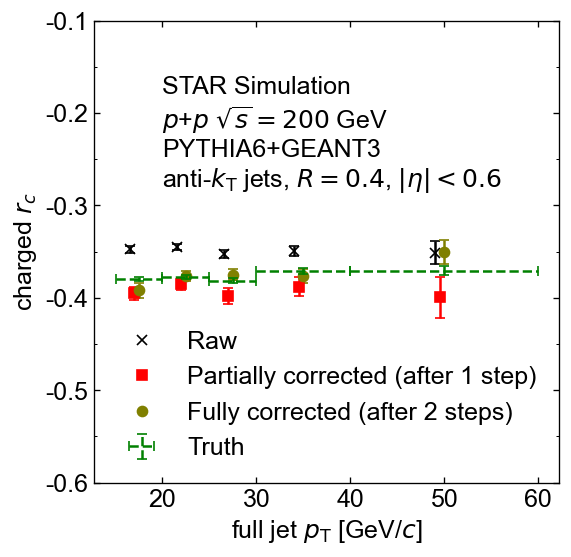

In [118]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none')
plt.errorbar([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, yerr=rc_err_fakesubtracted_array, capsize=3, color='r', ls='none')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, yerr=np.sqrt((np.asarray(rc_err_match_bs_vs_pt_array))**2+(np.asarray(rc_rwerr_match_bs_vs_pt_array))**2), capsize=3, color='olive', ls='none')
plt.plot([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, color='k', ls='none', marker='x', label='Raw')
plt.plot([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
plt.plot([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, color='olive', ls='none', marker='o', label='Fully corrected (after 2 steps)')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc2_truth_b_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc2_err_truth_b_vs_pt_array, capsize=3, color='g', ls='none', label='Truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')

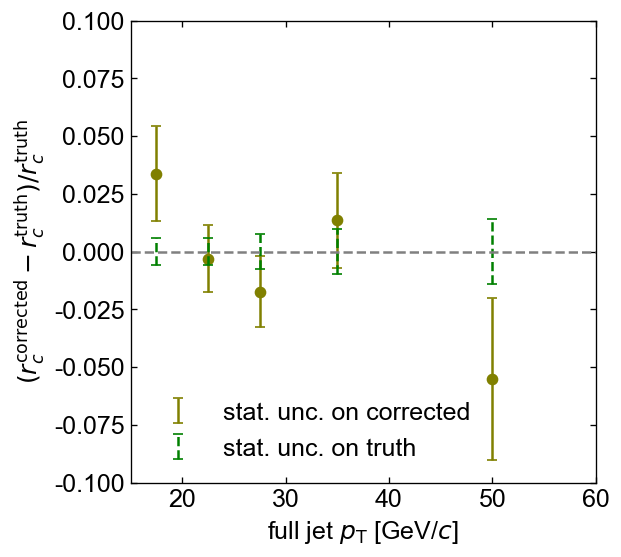

In [134]:
fig=plt.figure(figsize=(5,5))
#plt.errorbar([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, yerr=rc2_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none')
#plt.errorbar([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, yerr=rc_err_fakesubtracted_array, capsize=3, color='r', ls='none')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], (np.asarray(rc_match_bs_vs_pt_array)-np.asarray(rc2_truth_b_vs_pt_array))/np.asarray(rc2_truth_b_vs_pt_array), yerr=np.sqrt((np.asarray(rc_err_match_bs_vs_pt_array))**2+(np.asarray(rc_rwerr_match_bs_vs_pt_array))**2)/abs(np.asarray(rc2_truth_b_vs_pt_array)), capsize=3, color='olive', ls='none', label='stat. unc. on corrected')
#plt.plot([16.5, 21.5, 26.5, 34., 49], rc2_allreco_bs_vs_pts_array, color='k', ls='none', marker='x', label='Raw')
#plt.plot([17, 22, 27, 34.5, 49.5], rc_fakesubtracted_array, color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
plt.plot([17.5, 22.5, 27.5, 35, 50], (np.asarray(rc_match_bs_vs_pt_array)-np.asarray(rc2_truth_b_vs_pt_array))/np.asarray(rc2_truth_b_vs_pt_array), color='olive', ls='none', marker='o')
eb1 = plt.errorbar([17.5, 22.5, 27.5, 35, 50], np.zeros(5), yerr=np.asarray(rc2_err_truth_b_vs_pt_array)/abs(np.asarray(rc2_truth_b_vs_pt_array)), capsize=3, color='g', ls='none', label='stat. unc. on truth')
eb1[-1][0].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$(r_c^{\mathrm{corrected}}-r_c^{\mathrm{truth}})/r_c^{\mathrm{truth}}$')
plt.ylim(-0.1,0.1)
plt.xlim(15, 60)
plt.legend(loc='lower left', frameon=False)
#plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')

In [136]:
# central points on olive
print((np.asarray(rc_match_bs_vs_pt_array)-np.asarray(rc2_truth_b_vs_pt_array))/np.asarray(rc2_truth_b_vs_pt_array))

[ 0.03370688 -0.00308724 -0.01732876  0.01344508 -0.05529114]


In [137]:
# error bars on olive
print(np.sqrt((np.asarray(rc_err_match_bs_vs_pt_array))**2+(np.asarray(rc_rwerr_match_bs_vs_pt_array))**2)/abs(np.asarray(rc2_truth_b_vs_pt_array)))

[0.02048957 0.01454269 0.01556165 0.02061834 0.03515437]


In [135]:
# error bars on green
print(np.asarray(rc2_err_truth_b_vs_pt_array)/abs(np.asarray(rc2_truth_b_vs_pt_array)))

[0.00599725 0.00579607 0.00753613 0.00988389 0.01403024]


In [138]:
0.03370688 - 0.02048957 - 0.00599725 

0.007220060000000003

In [140]:
-0.05529114 + 0.03515437 + 0.01403024

-0.006106530000000006